# Descriptives

## TOC 

- [Setup](#setup)
- [Load, Partition, and Sample Tweets/Batches for Labeling](#load_tweets)
- [Compare Prevalences](#compare_prevalences)
- [Check for Order Effects](#order_effects)

# Stuff to Check For / Analysis Ideas
- compare prevalences with those from Kern et al Paper 
- calculate agreement per tweets across the different conditions
- compare uncertainty measures per conditions (empirical entropy, confidence scores, etc.)
- order effects (compare batch prompted with single-tweet prompted tweets)

In [206]:
# General Setup and Git
# cd to path of current script
import os
import sys
os.chdir(sys.path[0])

! git pull

Already up to date.


In [205]:
# Git codes
## see git status
! git status # see git status

# Ask the user for a commit message
commit_message = input("Enter commit message: ")

## Git add the current stuff to commit and set commit message
! git add .
! git commit -m "$commit_message"

## Push commits to remote
! git push

On branch master
Your branch is up to date with 'origin/master'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .DS_Store
	modified:   .ipynb_checkpoints/4a_GPT_Labeling-checkpoint.ipynb
	modified:   .ipynb_checkpoints/4b_GPT_Label_Descriptives-checkpoint.ipynb
	modified:   .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace
	modified:   4a_GPT_Labeling.ipynb
	modified:   4b_GPT_Label_Descriptives.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


Enter commit message:  First Descriptive Analyses


[master 89d6761] First Descriptive Analyses
 6 files changed, 3165 insertions(+), 1138 deletions(-)
 rewrite .jupyter/desktop-workspaces/default-37a8.jupyterlab-workspace (89%)
Enumerating objects: 16, done.
Counting objects: 100% (16/16), done.
Delta compression using up to 8 threads
Compressing objects: 100% (8/8), done.
Writing objects: 100% (9/9), 208.04 KiB | 3.36 MiB/s, done.
Total 9 (delta 5), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (5/5), completed with 5 local objects.
To github.com:T-Reiter/master-thesis.git
   5576960..89d6761  master -> master


<a id="setup"></a>
## SANDBOX & SETUP

<a id="load_tweets"></a>
## Load and Preprocess the GPT Labelled Tweets

In [218]:
# load the full tweets as used by CK
import pandas as pd
# pd.set_option('max_colwidth', 1000)
pd.set_option('display.max_colwidth', 0)

# Load the tweet files
folder_path = 'Tweets_CK/'
train_file = 'full_train_s.csv'
test_file = 'full_test_s.csv'

train_df = pd.read_csv(os.path.join(folder_path, train_file))
test_df = pd.read_csv(os.path.join(folder_path, test_file))

# Reorder test_df columns to match train_df
test_df = test_df[train_df.columns]

# Add the 'original_split' column
train_df['original_split'] = 'train'
test_df['original_split'] = 'test'

# Combine them
tweets_full = pd.concat([train_df, test_df], ignore_index=True)

# Rename columns for a consistent style 
tweets_full = (tweets_full.
               rename(columns={'tweet.id': 'tweet_id', 
                               'batch.tweet': 'batch_tweet',
                               'hate.speech': 'hate_speech', 
                               'offensive.language': 'offensive_language'}))

In [219]:
# Get the Summary Table
(tweets_full
 .groupby('version').agg(
    Annotations=('tweet_id', 'count'),
    Annotators=('id', 'nunique'),
    OL=('offensive_language', 'mean'),
    HS=('hate_speech', 'mean')  
).round(3))


,Annotations,Annotators,OL,HS
version,,,,
A,9000,184,0.516,0.268
B,9000,183,0.588,0.296
C,8950,182,0.585,0.282
D,8950,179,0.544,0.335
E,9000,189,0.590,0.318


### Load and rbind the GPT Labeled Tweets

In [65]:
import os
import pandas as pd

DATE_TO_IMPORT = '2025_04_10'

files = os.listdir('Data_Collection/')
files_to_select = list(filter(lambda filename: filename.startswith(DATE_TO_IMPORT), files))
files_to_select = [f"Data_Collection/{filename}" for filename in files_to_select]

# read and concat files 
dataframes = [pd.read_csv(file) for file in files_to_select]
combined_df = pd.concat(dataframes, sort=False, ignore_index=True)
combined_df.sort_values(['batch_id', 'tweet_in_batch'], inplace=True)

### Get to Long Format

In [86]:
# Get from Wide Format to Proper Long Format
### List of columns that are shared among all tweets
shared_cols = ['batch_id', 'tweet_in_batch', 'tweet_id', 'tweet', 'condition']

### List to hold the DataFrame for each responder
df_list = []

# Loop over each responder identifier (R1, R2, R3)
for responder in ['R1', 'R2', 'R3']:
    # Create a new DataFrame from old columns and responder col
    df_temp = combined_df[shared_cols].copy()
    df_temp['responder'] = responder

    # Add the responder-specific columns by using the respective column names
    df_temp['label'] = combined_df[f'{responder}_label']
    df_temp['score'] = combined_df[f'{responder}_score']
    df_temp['Token1'] = combined_df[f'{responder}_Token1']
    df_temp['Token2'] = combined_df[f'{responder}_Token2']
    df_temp['Token3'] = combined_df[f'{responder}_Token3']

    # Append the new DataFrame to the list
    df_list.append(df_temp)

# Concatenate all responder DataFrames into one
df_long = pd.concat(df_list, ignore_index=True)

### Get binary OL and HS identifier columns

In [119]:
df_long['OL'] = np.where(['OL' in label for label in df_long['label']], 1, 0)
df_long['HS'] = np.where(['HS' in label for label in df_long['label']], 1, 0)
df_long.head(5)

,batch_id,tweet_in_batch,tweet_id,tweet,condition,responder,label,score,Token1,Token2,Token3,OL,HS
0,100,1,1657,@###### Roberts is a fuckin fag&#128514; smack...,A_conf,R1,OLHS,4.0,OL -0.000058 \n* -9.750058 \n OL -16....,"HS -4.320200e-07\n, -1.500000e+01\nH ...",", -4.320200e-07\n , -1.500000e+01\n', -...",1,1
1,100,1,1657,@###### Roberts is a fuckin fag&#128514; smack...,B_conf,R1,HSOL,4.0,HS -0.000028 \n* -10.500028\n HS -17....,"OL -0.000022 \n, -10.750022\nO -16....",", -0.000022 \n , -10.750022\n', -16.250...",1,1
2,100,1,1657,@###### Roberts is a fuckin fag&#128514; smack...,C.OL_conf,R1,OL,4.0,OL -0.000008 \n* -11.750008\n OL -16....,", 0.000 \n , -17.625\n', -20.500\n， ...",0.000 \n4 -17.625\n3 -20....,1,0
3,100,1,1657,@###### Roberts is a fuckin fag&#128514; smack...,C.HS_conf,R1,HS,4.0,HS -0.000003 \n* -12.750003\n HS -17....,", 0.000 \n , -17.875\n', -20.125\n， ...",0.000 \n4 -17.875\n3 -20....,0,1
4,100,1,1657,@###### Roberts is a fuckin fag&#128514; smack...,A_batch,R1,OLHS,NaN,NaN,NaN,NaN,1,1


<a id="compare_prevalences"></a>
## Compute and Compare Overall Prevalences with those of the AS Paper

In [221]:
# Compare HS and OL count across conditions 
tasks = ['A','B','C.OL', 'C.HS']
modes = ['', '_conf', '_batch', '_batch_conf']
custom_order = [t + m for m in modes for t in tasks]

(df_long
 .groupby('condition')
 .mean(['OL', 'HS', 'score'])
 .round(2)
 [['OL', 'HS', 'score']]
 .reindex(custom_order)
 .head(5))

,OL,HS,score
condition,,,
A,0.85,0.58,NaN
B,0.75,0.53,NaN
C.OL,0.80,0.00,NaN
C.HS,0.00,0.67,NaN
A_conf,0.90,0.57,3.5


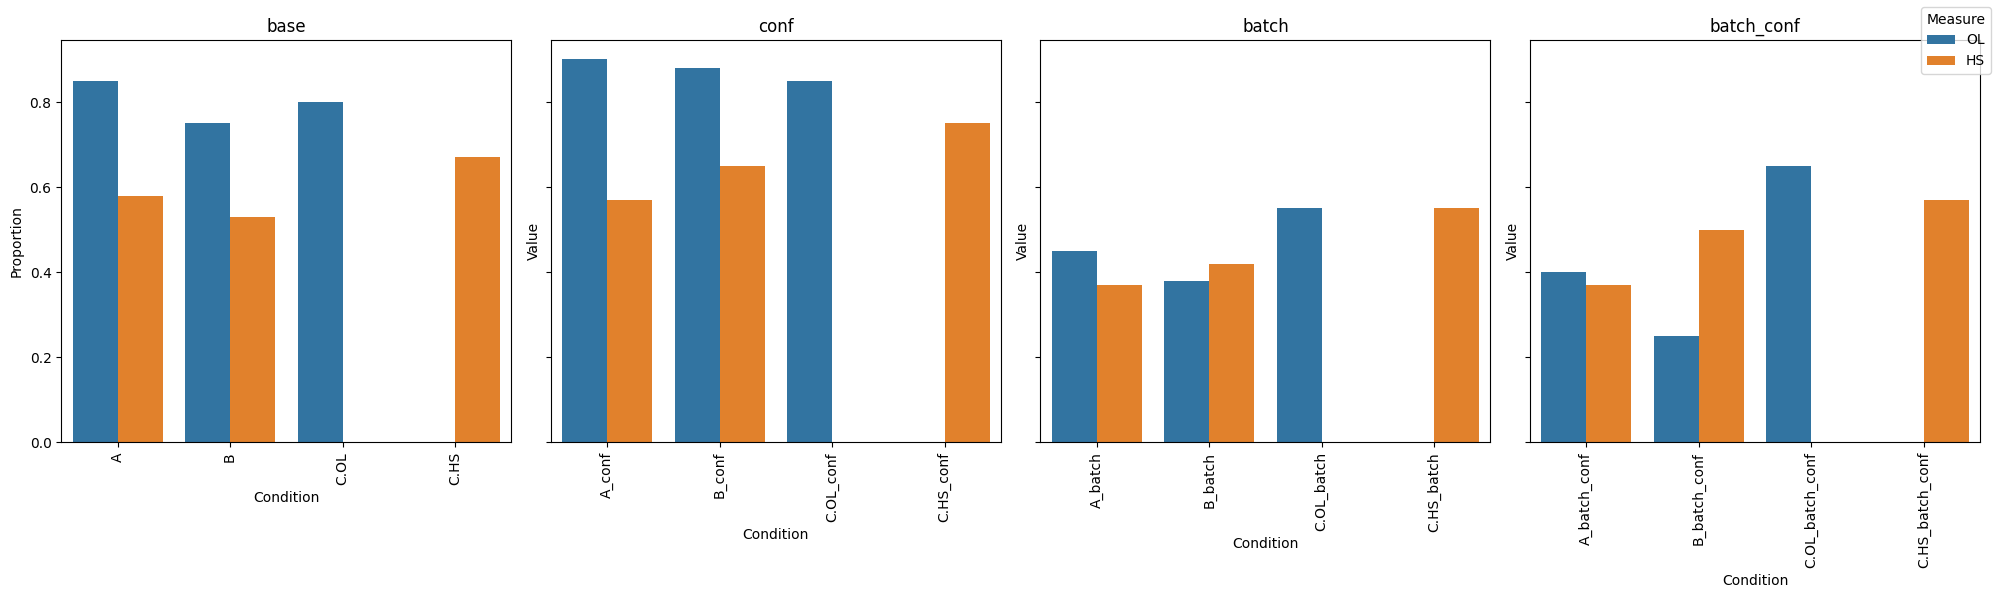

In [207]:
# Optionally, extract the base condition (everything before any underscore).
df['base_condition'] = df['condition'].apply(lambda x: x.split('_')[0])

# A custom function to extract the correct group type.
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

# Create a column for the group type.
df['group_type'] = df['condition'].apply(extract_group_type)

# Melt the DataFrame to have one row per condition-measure combination.
df_melt = df.melt(
    id_vars=['condition', 'base_condition', 'group_type'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Value'
)

# Define the desired order for our groups.
group_order = ['base', 'conf', 'batch', 'batch_conf']

# Create subplots – one subplot per group type.
fig, axes = plt.subplots(nrows=1, ncols=len(group_order), figsize=(20, 6), sharey=True)


for ax, grp in zip(axes, group_order):
    # Subset data for the current group type.
    df_grp = df_melt[df_melt['group_type'] == grp]
    
    # Create the order for conditions for the current group.
    if grp == 'base':
        cond_order = [cond for cond in custom_order if '_' not in cond]
    elif grp == 'conf':
        # Select conditions that end with '_conf' but NOT with '_batch_conf'
        cond_order = [cond for cond in custom_order if cond.endswith('_conf') and not cond.endswith('_batch_conf')]
    elif grp == 'batch':
        # Select conditions that end with '_batch' (and not batch_conf because that is handled separately)
        cond_order = [cond for cond in custom_order if cond.endswith('_batch') and not cond.endswith('_batch_conf')]
    elif grp == 'batch_conf':
        cond_order = [cond for cond in custom_order if cond.endswith('_batch_conf')]
    
    # Plot the grouped barplot for this subgroup.
    sns.barplot(
        data=df_grp,
        x='condition',
        y='Value',
        hue='Measure',
        order=cond_order,  # enforce the correct ordering
        dodge=True,
        ax=ax, 
        palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
                   'HS': '#ff7f0e'}
    )
    
    ax.set_title(grp)
    ax.set_xlabel("Condition")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.legend().remove()

# Set a common y-axis label.
axes[0].set_ylabel("Proportion")

# Add a single common legend.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Measure", loc="upper right")

plt.tight_layout()
plt.show()

Notes to the above, it seems as:  
- asking for a confidence score in general increases the OS/HS labelling probability
- using batch prompting in general decreases the labelling probability (rather strong) 

<a id="order_effects"></a>
## Order Effects in Batch Prompting Tasks?

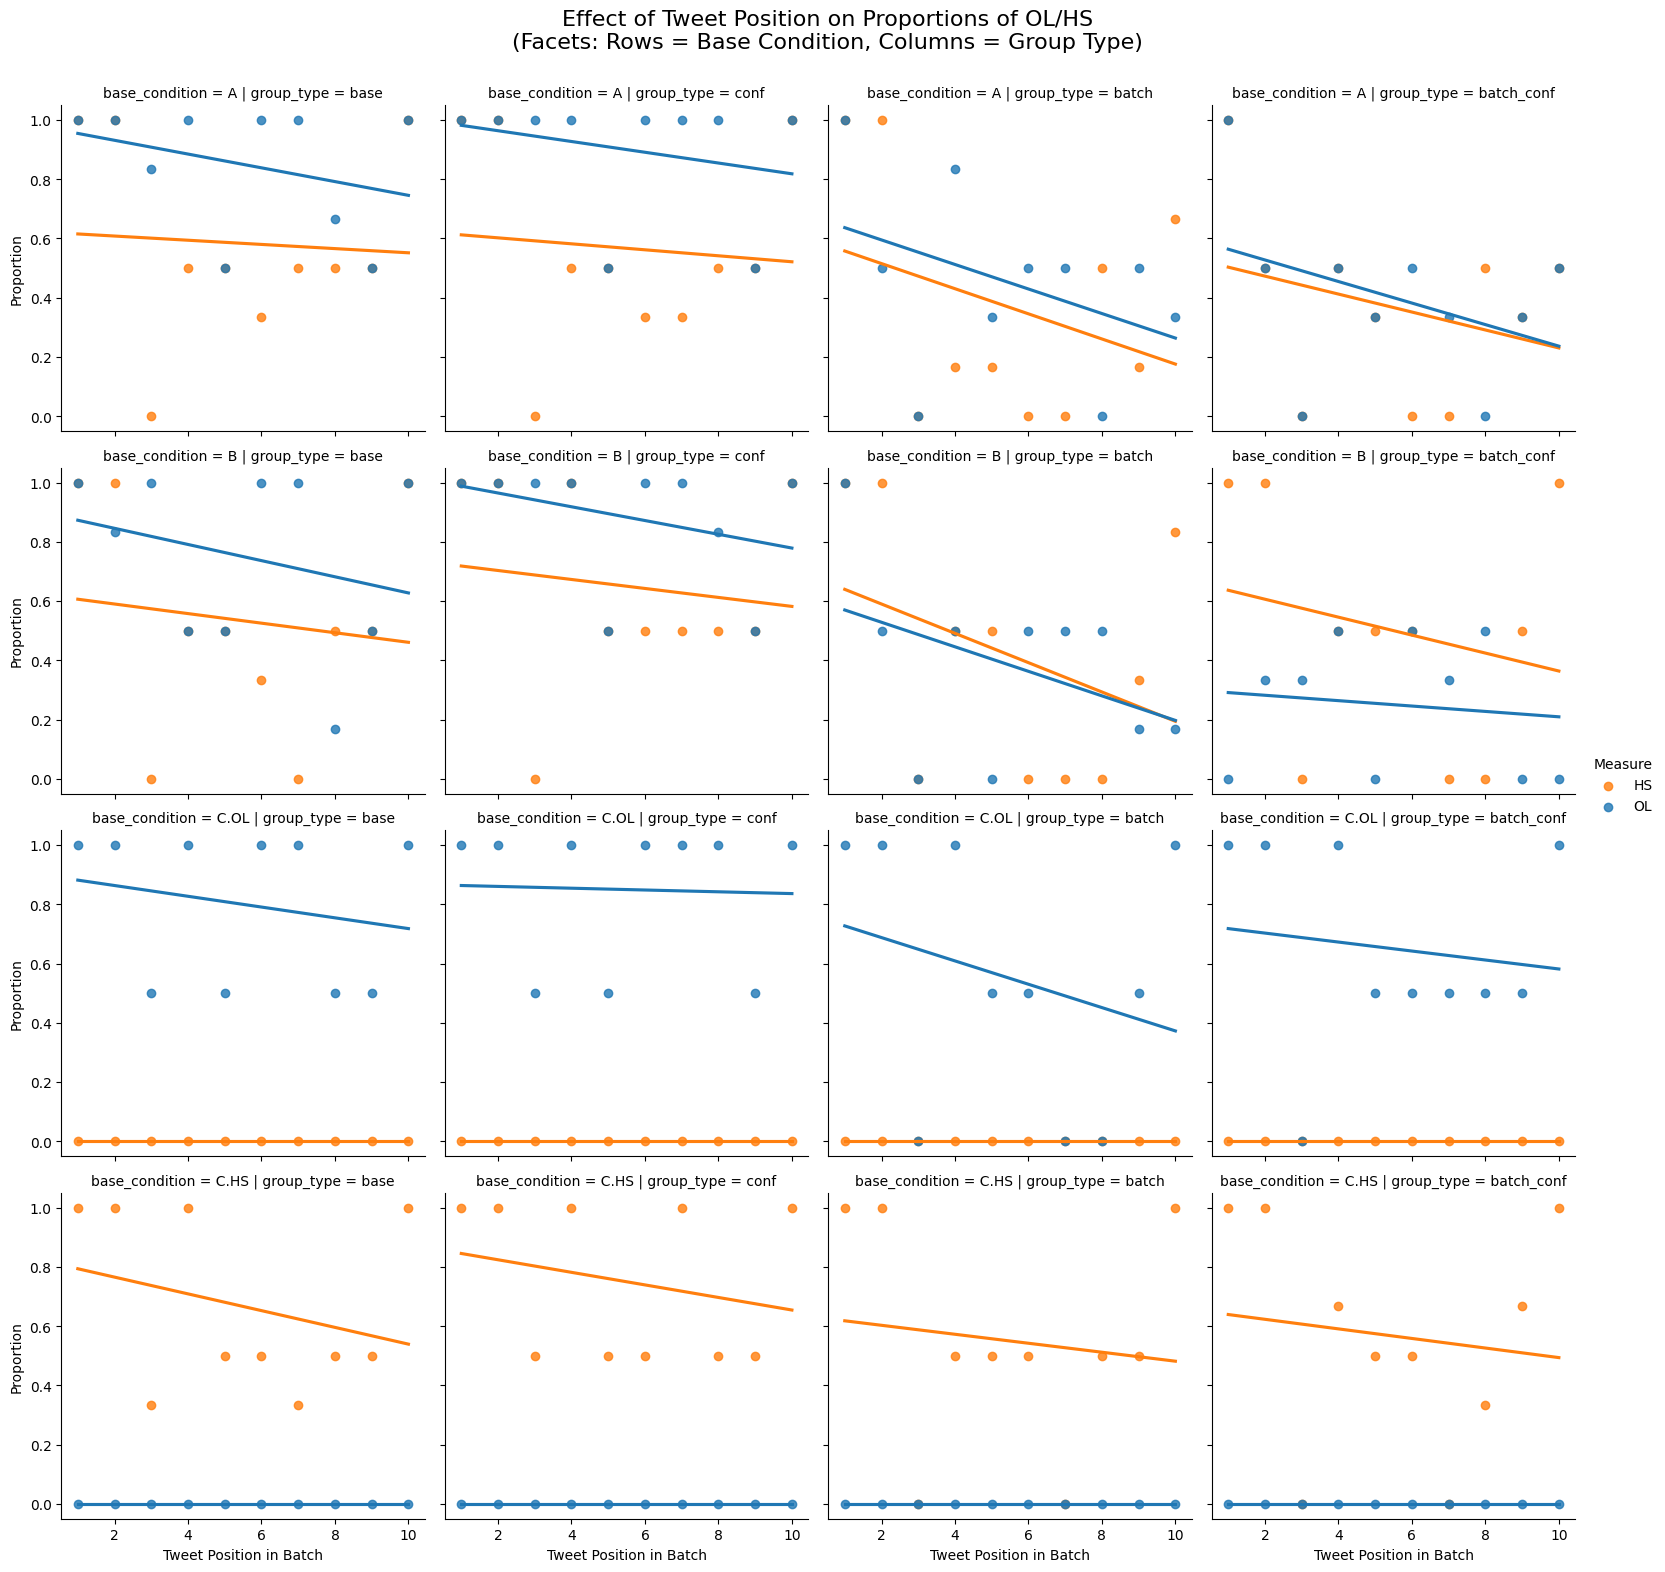

In [203]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------
# 1. Data Preparation
# ---------------------------
# It is assumed that df_long exists and has columns:
#   - 'condition'
#   - 'tweet_in_batch'
#   - 'OL' and 'HS' (binary: 1 if labeled, 0 otherwise)

# Reshape the data from wide to long: each tweet gets one row per measure
df_melt = df_long.melt(
    id_vars=['condition', 'tweet_in_batch'],
    value_vars=['OL', 'HS'],
    var_name='Measure',
    value_name='Label'
)

# Group by condition, tweet_in_batch, and measure to compute the proportion
# (since Label is binary, the mean gives the proportion)
df_prop = df_melt.groupby(
    ['condition', 'tweet_in_batch', 'Measure'], as_index=False
)['Label'].mean()
df_prop.rename(columns={'Label': 'Proportion'}, inplace=True)

# ---------------------------
# 2. Extract Condition Info
# ---------------------------
# Create column for the base condition: if there's an underscore, take the part before it; otherwise, use the whole condition
df_prop['base_condition'] = df_prop['condition'].apply(lambda x: x.split('_')[0])

# Create a custom function to extract the group type.
# We want to make sure that for conditions such as "A_batch_conf" we get 'batch_conf'
def extract_group_type(x):
    if '_' not in x:
        return 'base'
    elif x.endswith('_batch_conf'):
        return 'batch_conf'
    elif x.endswith('_conf'):
        return 'conf'
    elif x.endswith('_batch'):
        return 'batch'
    else:
        return 'other'

df_prop['group_type'] = df_prop['condition'].apply(extract_group_type)

# ---------------------------
# 3. Set the Category Orders
# ---------------------------
# For columns in the facet grid, set the order of group types and base conditions.
desired_group_order = ['base', 'conf', 'batch', 'batch_conf']
df_prop['group_type'] = pd.Categorical(df_prop['group_type'],
                                       categories=desired_group_order,
                                       ordered=True)

desired_base_order = ['A', 'B', 'C.OL', 'C.HS']
df_prop['base_condition'] = pd.Categorical(df_prop['base_condition'],
                                           categories=desired_base_order,
                                           ordered=True)

# ---------------------------
# 4. Plot with lmplot in a FacetGrid
# ---------------------------
# In each facet, tweet_in_batch is on x, and the y is the proportion.
# Each facet (given by the row and column) will have two regression lines (one per Measure).
g = sns.lmplot(
    data=df_prop,
    x='tweet_in_batch',
    y='Proportion',
    hue='Measure',              # Two lines: one for OL and one for HS
    col='group_type',           # Columns: base, conf, batch, batch_conf
    row='base_condition',       # Rows: A, B, C.OL, C.HS
    markers='o',                # Use circles for the data points
    ci=None,                    # Disable the confidence interval shading (adjust if needed)
    height=4,                   # Height of each facet
    aspect=1,                   # Aspect ratio
    order=1,                     # Linear (OLS) regression
    palette = {'OL': '#1f77b4', # hex colors as of jacobs paper
               'HS': '#ff7f0e'}
)

g.set_axis_labels("Tweet Position in Batch", "Proportion")
g.fig.subplots_adjust(top=0.92)
g.fig.suptitle("Effect of Tweet Position on Proportions of OL/HS\n(Facets: Rows = Base Condition, Columns = Group Type)", fontsize=16)

plt.show()
